# Dataset Normalization Comparison
Compares the `data_mean` and `data_std` across all Pangaea downstream segmentation datasets.
All values are converted to a common **reflectance [0, 1]** scale for fair comparison.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

plt.rcParams.update({'font.size': 11, 'figure.dpi': 130})

## 1. Raw statistics from dataset YAML configs

In [2]:
# ── Optical band ordering ──────────────────────────────────────────────────
# Listed in the order they appear in each dataset config.
# Scale: factor to multiply mean/std to reach [0, 1] reflectance.
DATASETS = {
    "AI4SmallFarms": dict(
        scale=1/10000,
        bands=["B2","B3","B4","B8"],
        mean=[750.2136, 1032.7277, 1165.1279, 2416.0448],
        std =[283.3842, 332.7280, 518.9025, 702.3791],
    ),
    "CropTypeMapping": dict(
        scale=1/10000,
        bands=["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"],
        mean=[2031.17, 1961.43, 1979.41, 2145.66, 2700.29, 3006.88, 2870.53, 3215.06, 2367.77, 1645.22],
        std =[2112.21, 2027.46, 2136.80, 2100.73, 2082.19, 2142.97, 2071.28, 2152.29, 1334.55, 1059.04],
    ),
    "DynamicEarthNet": dict(
        scale=1/10000,
        bands=["B2","B3","B4","B5"],
        mean=[671.26, 915.62, 1042.59, 2605.21],
        std =[596.94, 715.55, 957.96, 1059.90],
    ),
    "FiveBillionPixels": dict(
        scale=1/255,   # GF-2 uint8
        bands=["B8","B4","B3","B2"],
        mean=[92.6, 124.3, 94.2, 98.0],
        std =[44.5, 51.0, 50.0, 47.1],
    ),
    "HLSBurnScars": dict(
        scale=1.0,     # already [0,1] reflectance
        bands=["B2","B3","B4","B8A","B11","B12"],
        mean=[0.03335, 0.05701, 0.05890, 0.23232, 0.19729, 0.11945],
        std =[0.02269, 0.02681, 0.04004, 0.07792, 0.08709, 0.07242],
    ),
    "MADOS": dict(
        scale=1.0,     # already [0,1] reflectance
        bands=["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"],
        mean=[0.05827, 0.05223, 0.04381, 0.03571, 0.03413, 0.03680, 0.03999, 0.03567, 0.03965, 0.02680, 0.01979],
        std =[0.03241, 0.03432, 0.03548, 0.03758, 0.03785, 0.04992, 0.05884, 0.05546, 0.06424, 0.04211, 0.03019],
    ),
    "PASTIS": dict(
        scale=1/10000,
        bands=["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"],
        mean=[1161.68, 1371.43, 1423.41, 1759.73, 2714.53, 3055.84, 3197.90, 3313.36, 2415.97, 1626.84],
        std =[2045.07, 1983.18, 2060.80, 1968.82, 1867.22, 1885.14, 1897.51, 1885.16, 1542.77, 1375.25],
    ),
    "Sen1Floods11": dict(
        scale=1/10000,
        bands=["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B10","B11","B12"],
        mean=[1626.92, 1396.03, 1364.06, 1218.23, 1466.07, 2386.90, 2845.61, 2622.96, 3077.48, 486.87, 63.78, 2030.65, 1179.17],
        std =[700.17, 739.09, 735.25, 864.94, 776.88, 921.37, 1084.37, 1022.63, 1196.44, 336.61, 143.99, 980.87, 764.61],
    ),
    "SpaceNet7": dict(
        scale=1/255,   # Planet RGB uint8
        bands=["B4","B3","B2"],
        mean=[121.826, 106.528, 78.372],
        std =[56.717, 44.517, 40.452],
    ),
    "SpaceNet7CD": dict(
        scale=1/255,
        bands=["B4","B3","B2"],
        mean=[121.826, 106.528, 78.372],
        std =[56.717, 44.517, 40.452],
    ),
}

# Normalize to [0,1] reflectance
for ds, info in DATASETS.items():
    s = info["scale"]
    info["mean_norm"] = [v * s for v in info["mean"]]
    info["std_norm"]  = [v * s for v in info["std"]]

print("Datasets loaded:", list(DATASETS.keys()))

Datasets loaded: ['AI4SmallFarms', 'CropTypeMapping', 'DynamicEarthNet', 'FiveBillionPixels', 'HLSBurnScars', 'MADOS', 'PASTIS', 'Sen1Floods11', 'SpaceNet7', 'SpaceNet7CD']


## 2. Per-band mean and std across datasets
Each dataset is a line; x-axis = S2 band ordered by wavelength.

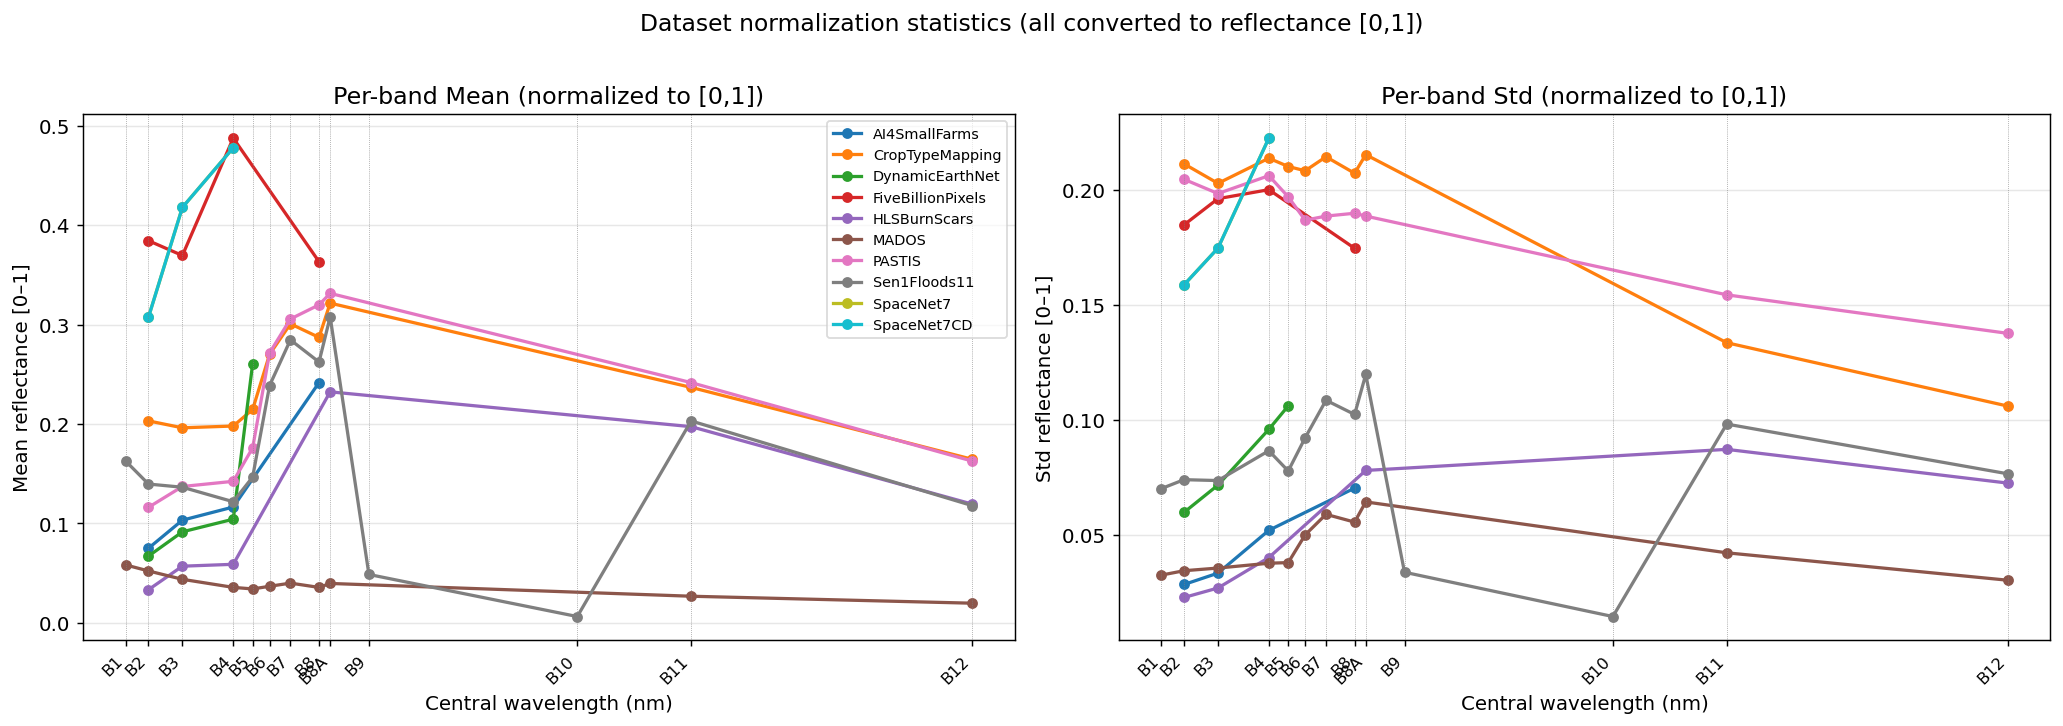

In [7]:
# Canonical S2 band order (by wavelength)
S2_ORDER = ["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B10","B11","B12"]
S2_WL    = {"B1":443,"B2":490,"B3":560,"B4":665,"B5":705,"B6":740,
             "B7":783,"B8":842,"B8A":865,"B9":945,"B10":1375,"B11":1610,"B12":2190}

COLORS = plt.cm.tab10(np.linspace(0, 1, len(DATASETS)))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=False)

for ax, key in zip(axes, ("mean_norm", "std_norm")):
    label = "Mean" if key == "mean_norm" else "Std"
    for (ds, info), color in zip(DATASETS.items(), COLORS):
        xs, ys = [], []
        for band, val in zip(info["bands"], info[key]):
            if band in S2_WL:
                xs.append(S2_WL[band])
                ys.append(val)
        order = np.argsort(xs)
        xs = [xs[i] for i in order]
        ys = [ys[i] for i in order]
        ax.plot(xs, ys, marker="o", markersize=5, label=ds, color=color, linewidth=1.8)

    ax.set_xlabel("Central wavelength (nm)")
    ax.set_ylabel(f"{label} reflectance [0–1]")
    ax.set_title(f"Per-band {label} (normalized to [0,1])")
    # add band name annotations at top
    for band in S2_ORDER:
        if band in S2_WL:
            ax.axvline(S2_WL[band], color="gray", linewidth=0.4, linestyle=":")
    ax.set_xticks([S2_WL[b] for b in S2_ORDER])
    ax.set_xticklabels(S2_ORDER, rotation=45, ha="right", fontsize=9)
    ax.grid(axis="y", alpha=0.3)

axes[0].legend(loc="upper right", fontsize=8, framealpha=0.7)
fig.suptitle("Dataset normalization statistics (all converted to reflectance [0,1])", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 3. Coefficient of variation (std / mean)
How much relative spread there is per band. High CV → the normalization will have to stretch/compress a lot.

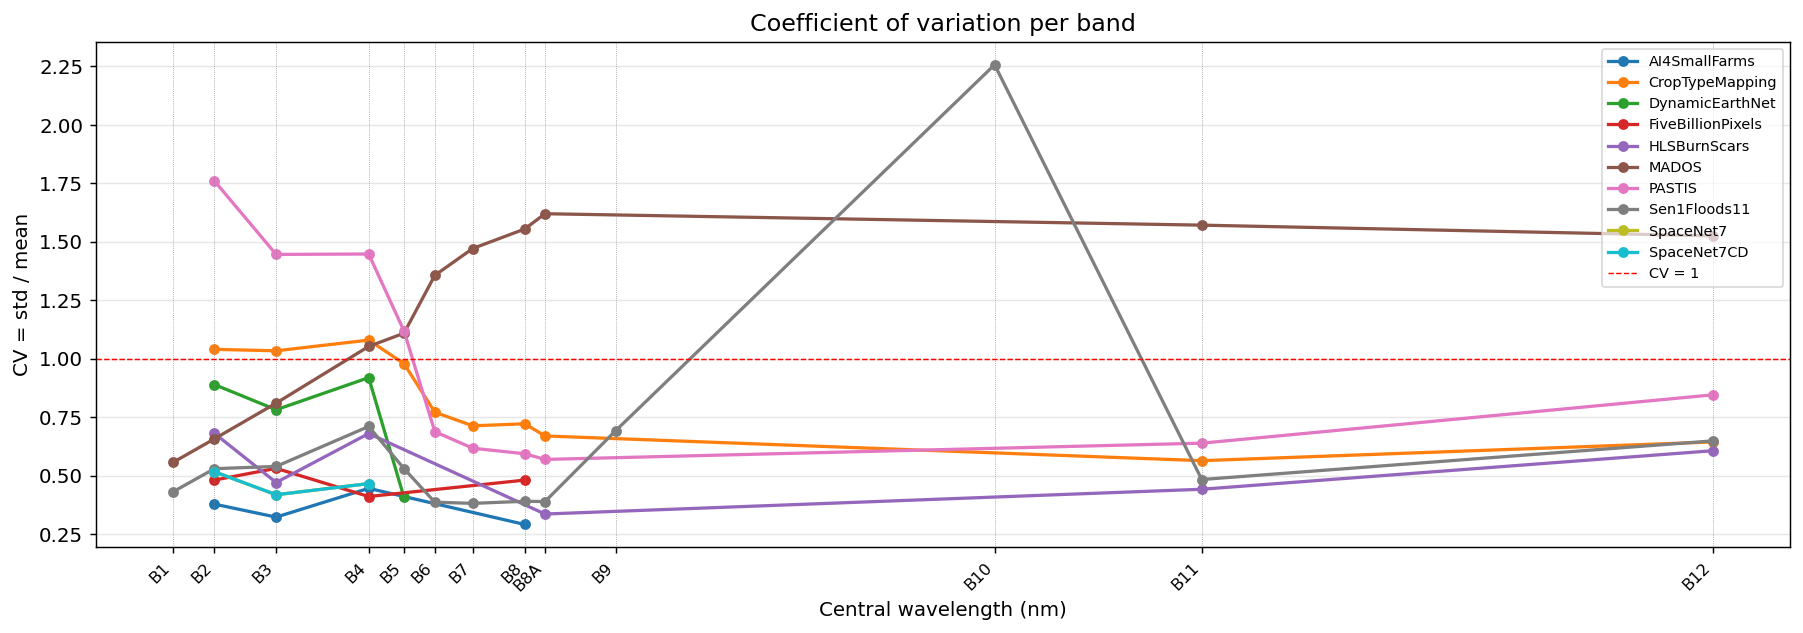

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))

for (ds, info), color in zip(DATASETS.items(), COLORS):
    xs, ys = [], []
    for band, m, s in zip(info["bands"], info["mean_norm"], info["std_norm"]):
        if band in S2_WL and m > 0:
            xs.append(S2_WL[band])
            ys.append(s / m)
    order = np.argsort(xs)
    xs = [xs[i] for i in order]
    ys = [ys[i] for i in order]
    ax.plot(xs, ys, marker="o", markersize=5, label=ds, color=color, linewidth=1.8)

for band in S2_ORDER:
    if band in S2_WL:
        ax.axvline(S2_WL[band], color="gray", linewidth=0.4, linestyle=":")
ax.set_xticks([S2_WL[b] for b in S2_ORDER])
ax.set_xticklabels(S2_ORDER, rotation=45, ha="right", fontsize=9)
ax.set_xlabel("Central wavelength (nm)")
ax.set_ylabel("CV = std / mean")
ax.set_title("Coefficient of variation per band")
ax.axhline(1.0, color="red", linewidth=0.8, linestyle="--", label="CV = 1")
ax.legend(fontsize=8, framealpha=0.7)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Heatmap: mean reflectance per dataset × band

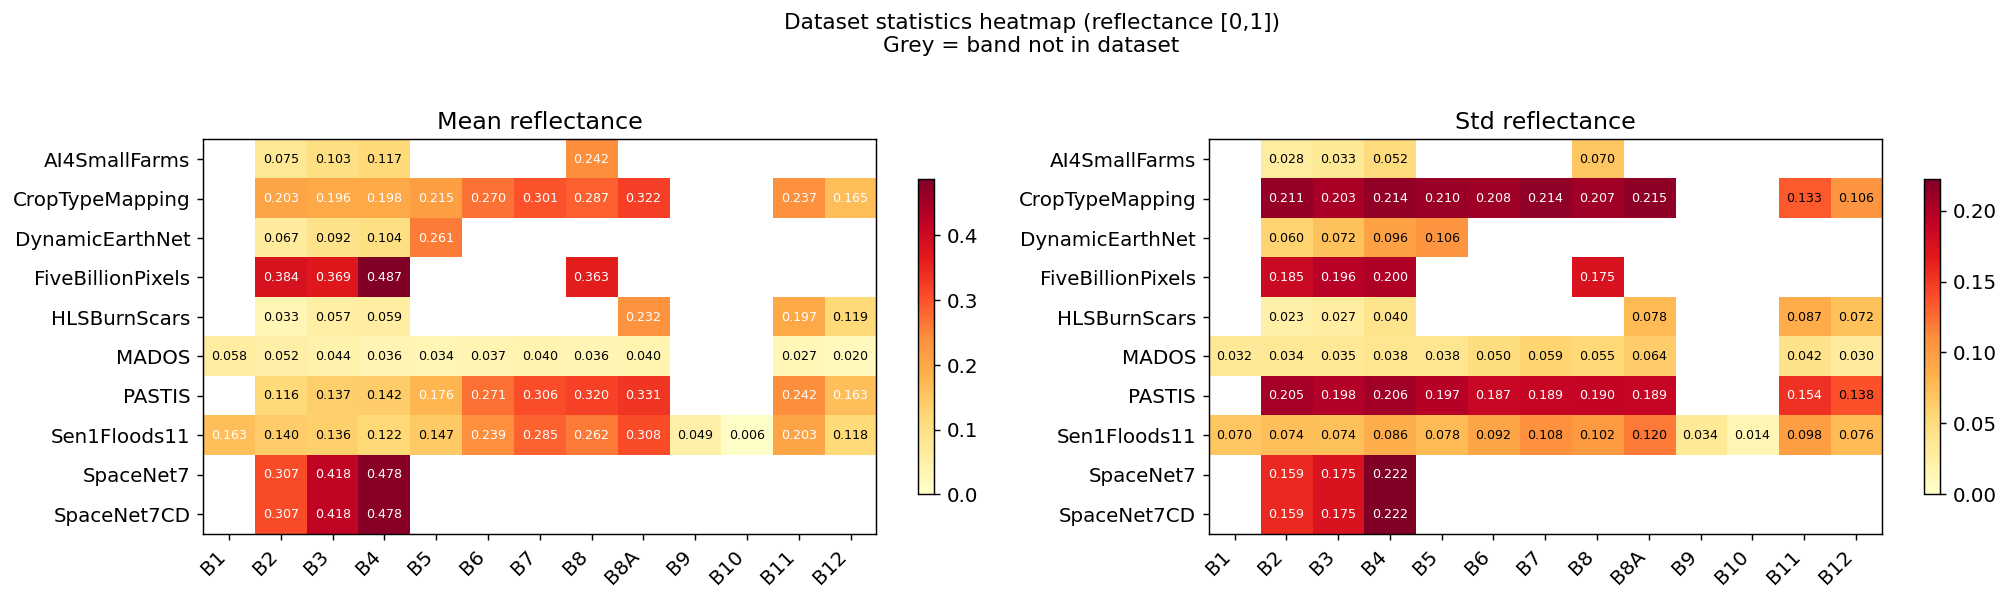

In [5]:
all_bands_seen = sorted(
    {b for info in DATASETS.values() for b in info["bands"] if b in S2_WL},
    key=lambda b: S2_ORDER.index(b) if b in S2_ORDER else 99
)

ds_names = list(DATASETS.keys())
mean_matrix = np.full((len(ds_names), len(all_bands_seen)), np.nan)
std_matrix  = np.full((len(ds_names), len(all_bands_seen)), np.nan)

for i, (ds, info) in enumerate(DATASETS.items()):
    for band, m, s in zip(info["bands"], info["mean_norm"], info["std_norm"]):
        if band in all_bands_seen:
            j = all_bands_seen.index(band)
            mean_matrix[i, j] = m
            std_matrix[i, j]  = s

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

for ax, mat, title in zip(axes, [mean_matrix, std_matrix], ["Mean reflectance", "Std reflectance"]):
    im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0)
    ax.set_xticks(range(len(all_bands_seen)))
    ax.set_xticklabels(all_bands_seen, rotation=45, ha="right")
    ax.set_yticks(range(len(ds_names)))
    ax.set_yticklabels(ds_names)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.8)
    # annotate cells
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if not np.isnan(mat[i, j]):
                ax.text(j, i, f"{mat[i,j]:.3f}", ha="center", va="center",
                        fontsize=7, color="black" if mat[i,j] < 0.15 else "white")

plt.suptitle("Dataset statistics heatmap (reflectance [0,1])\nGrey = band not in dataset",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 5. Summary table

In [6]:
rows = []
for ds, info in DATASETS.items():
    mn = info["mean_norm"]
    st = info["std_norm"]
    rows.append({
        "Dataset": ds,
        "Original scale": f"÷{int(1/info['scale'])}" if info["scale"] != 1.0 else "[0,1]",
        "Bands": ", ".join(info["bands"]),
        "N bands": len(mn),
        "Mean (min→max)": f"{min(mn):.3f} → {max(mn):.3f}",
        "Std  (min→max)": f"{min(st):.3f} → {max(st):.3f}",
        "Avg CV": f"{np.mean([s/m for m,s in zip(mn,st) if m>0]):.2f}",
    })

df = pd.DataFrame(rows).set_index("Dataset")
pd.set_option("display.max_colwidth", 60)
df

,Original scale,Bands,N bands,Mean (min→max),Std (min→max),Avg CV
Dataset,,,,,,
AI4SmallFarms,÷10000,"B2, B3, B4, B8",4,0.075 → 0.242,0.028 → 0.070,0.36
CropTypeMapping,÷10000,"B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12",10,0.165 → 0.322,0.106 → 0.215,0.82
DynamicEarthNet,÷10000,"B2, B3, B4, B5",4,0.067 → 0.261,0.060 → 0.106,0.75
FiveBillionPixels,÷255,"B8, B4, B3, B2",4,0.363 → 0.487,0.175 → 0.200,0.48
HLSBurnScars,"[0,1]","B2, B3, B4, B8A, B11, B12",6,0.033 → 0.232,0.023 → 0.087,0.54
MADOS,"[0,1]","B1, B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12",11,0.020 → 0.058,0.030 → 0.064,1.21
PASTIS,÷10000,"B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12",10,0.116 → 0.331,0.138 → 0.206,0.97
Sen1Floods11,÷10000,"B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B10, B11, B12",13,0.006 → 0.308,0.014 → 0.120,0.64
SpaceNet7,÷255,"B4, B3, B2",3,0.307 → 0.478,0.159 → 0.222,0.47
